# 01 — Learning Problem & EDA (Bab 4)
**Proyek:** Klasifikasi Sentimen Ulasan Aplikasi AI Chatbot di Indonesia
**Tahap lifecycle:** [L] Learning Problem — Data Understanding

Notebook ini mengisi Bab 4 README: informasi dataset (4.1–4.2), kondisi data (4.3), dan EDA dengan 3 visualisasi (4.4).
> Jalankan dari folder `notebooks/`. Dataset harus ada di `../data/indonesian_ai_chatbots_reviews.csv` (unduh dari Kaggle, lihat README).

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

SEED = 42
np.random.seed(SEED)
DATA_PATH = '../data/indonesian_ai_chatbots_reviews.csv'
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

ORDER = ['negatif', 'netral', 'positif']
COL = {'negatif': '#d9534f', 'netral': '#f0ad4e', 'positif': '#5cb85c'}
plt.rcParams.update({'font.size': 10})

## 4.1 Informasi Dataset

In [2]:
df = pd.read_csv(DATA_PATH)
df['at'] = pd.to_datetime(df['at'])

print(f'Jumlah baris  : {df.shape[0]:,}')
print(f'Jumlah kolom  : {df.shape[1]}')
print(f'Ukuran file   : {os.path.getsize(DATA_PATH):,} byte (~{os.path.getsize(DATA_PATH)/1e6:.1f} MB)')
print(f'Periode ulasan: {df["at"].min()}  s.d.  {df["at"].max()}')
print(f'Aplikasi ({df.appName.nunique()}): {sorted(df.appName.unique())}')

Jumlah baris  : 29,198
Jumlah kolom  : 15
Ukuran file   : 6,609,278 byte (~6.6 MB)
Periode ulasan: 2023-06-09 23:06:25  s.d.  2026-11-02 15:51:40
Aplikasi (8): ['Character.AI', 'ChatGPT', 'Claude', 'DeepSeek', 'Google Gemini', 'Grok', 'Microsoft Copilot', 'Perplexity']


## 4.2 Deskripsi Fitur

In [3]:
pd.DataFrame({'dtype': df.dtypes.astype(str), 'n_unik': df.nunique(), 'contoh': df.iloc[0].astype(str).str[:40]}).drop(index='userName')  # userName disembunyikan (privasi)

,dtype,n_unik,contoh
reviewId,str,29198,21ee8bff-764b-48f7-95a5-864cf1f39f31
appName,str,8,ChatGPT
appId,str,8,com.openai.chatgpt
content,str,23532,sangat membantu
score,int64,5,5
thumbsUpCount,int64,140,0
reviewCreatedVersion,str,873,1.2026.293
at,datetime64[us],29159,2026-11-02 15:51:40
replyContent,str,135,NaN
repliedAt,str,154,NaN


## 4.3 Kondisi Data

### Missing values

In [4]:
miss = pd.DataFrame({'jumlah': df.isna().sum(), 'persen': (df.isna().mean()*100).round(2)})
miss[miss.jumlah > 0]

,jumlah,persen
reviewCreatedVersion,6225,21.32
replyContent,29044,99.47
repliedAt,29044,99.47


### Duplikat dan label konflik

In [5]:
print('Duplikat reviewId     :', df.reviewId.duplicated().sum())
print('Duplikat baris utuh   :', df.duplicated().sum())
n_dup = df.content.duplicated().sum()
print(f'Duplikat teks content : {n_dup:,} ({n_dup/len(df)*100:.1f}%)')

n_label = df.groupby('content').sentiment.nunique()
conflict = n_label[n_label > 1]
print('Teks unik dengan label konflik:', len(conflict))
print('\nTeks paling sering berulang (huruf kecil):')
print(df.content.str.lower().str.strip().value_counts().head(8))

Duplikat reviewId     : 0
Duplikat baris utuh   : 0
Duplikat teks content : 5,666 (19.4%)
Teks unik dengan label konflik: 260

Teks paling sering berulang (huruf kecil):
content
bagus              1008
mantap              421
good                403
sangat membantu     338
ok                  296
keren               268
baik                249
sangat bagus        193
Name: count, dtype: int64


### Outlier (metode IQR)

In [6]:
rows = []
for col in ['contentLength', 'wordCount', 'thumbsUpCount']:
    q1, q3 = df[col].quantile([.25, .75]); upper = q3 + 1.5*(q3-q1)
    n = int((df[col] > upper).sum())
    rows.append([col, q1, q3, upper, n, round(n/len(df)*100, 2), df[col].max()])
pd.DataFrame(rows, columns=['kolom', 'Q1', 'Q3', 'batas_atas', 'n_outlier', 'persen', 'maks'])

,kolom,Q1,Q3,batas_atas,n_outlier,persen,maks
0,contentLength,13.0,107.0,248.0,2536,8.69,500
1,wordCount,2.0,17.0,39.5,2610,8.94,104
2,thumbsUpCount,0.0,0.0,0.0,6731,23.05,2743


### Imbalance

In [7]:
vc = df.sentiment.value_counts()
display(pd.DataFrame({'jumlah': vc, 'persen': (vc/len(df)*100).round(1)}))
print(f'Rasio kelas terbesar : terkecil = {vc.max()/vc.min():.2f} : 1')

,jumlah,persen
sentiment,,
positif,13921,47.7
negatif,10707,36.7
netral,4570,15.7


Rasio kelas terbesar : terkecil = 3.05 : 1


### Noise (emoji, karakter berulang, bahasa gaul, teks pendek)

In [8]:
c = df.content
emoji_re = r'[\U0001F300-\U0001FAFF\u2600-\u27BF]'
slang_re = r'\b(gak|ga|nggak|bgt|banget|yg|tdk|udh|aja|sih|kok|gk)\b'
eng_re   = r'\b(the|good|very|great|and|is|love|nice|best|bad|app)\b'
noise = {
    'emoji': c.str.contains(emoji_re).sum(),
    'karakter berulang (>=3)': c.str.contains(r'(.)\1{2,}').sum(),
    'bahasa gaul (estimasi daftar kata)': c.str.lower().str.contains(slang_re).sum(),
    'campuran Inggris (estimasi daftar kata)': c.str.lower().str.contains(eng_re).sum(),
    'ulasan 1-2 kata': (df.wordCount <= 2).sum(),
}
pd.DataFrame({'jumlah': noise, 'persen': {k: round(v/len(df)*100, 1) for k, v in noise.items()}})

/tmp/ipykernel_160/1934702837.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'karakter berulang (>=3)': c.str.contains(r'(.)\1{2,}').sum(),
/tmp/ipykernel_160/1934702837.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'bahasa gaul (estimasi daftar kata)': c.str.lower().str.contains(slang_re).sum(),
/tmp/ipykernel_160/1934702837.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'campuran Inggris (estimasi daftar kata)': c.str.lower().str.contains(eng_re).sum(),


,jumlah,persen
emoji,2813,9.6
karakter berulang (>=3),2498,8.6
bahasa gaul (estimasi daftar kata),8089,27.7
campuran Inggris (estimasi daftar kata),2761,9.5
ulasan 1-2 kata,8281,28.4


### Potensi kebocoran label (leakage) dan kualitas data

In [9]:
# 1) Label diturunkan dari rating: score menentukan sentiment secara deterministik -> TIDAK boleh jadi fitur
display(pd.crosstab(df.score, df.sentiment))

# 2) contentLength dan wordCount konsisten dengan content?
print('contentLength tidak cocok:', (df.content.str.len() != df.contentLength).sum())
print('wordCount tidak cocok    :', (df.content.str.split().str.len() != df.wordCount).sum())

# 3) Sebaran waktu dan aplikasi
print('\nUlasan per tahun:'); print(df['at'].dt.year.value_counts().sort_index())
print('\nRentang waktu per aplikasi:'); print(df.groupby('appName')['at'].agg(['min', 'max']))

sentiment,negatif,netral,positif
score,,,
1,6597,0,0
2,4110,0,0
3,0,4570,0
4,0,0,5921
5,0,0,8000


contentLength tidak cocok: 0


wordCount tidak cocok    : 0

Ulasan per tahun:
at
2023       84
2024      806
2025     4050
2026    24258
Name: count, dtype: int64

Rentang waktu per aplikasi:
                                  min                 max
appName                                                  
Character.AI      2025-10-28 15:10:29 2026-11-02 11:05:50
ChatGPT           2026-06-05 07:43:25 2026-11-02 15:51:40
Claude            2024-07-22 05:57:02 2026-11-02 15:22:26
DeepSeek          2025-01-27 19:19:37 2026-11-01 23:49:49
Google Gemini     2026-04-10 11:12:45 2026-11-02 15:48:49
Grok              2025-03-24 16:00:53 2026-11-02 15:00:10
Microsoft Copilot 2023-12-29 02:51:04 2026-10-31 10:03:58
Perplexity        2023-06-09 23:06:25 2026-11-01 20:36:02


## 4.4 Exploratory Data Analysis

### Visualisasi 1 — Distribusi kelas dan komposisi per aplikasi

/tmp/ipykernel_160/2955319662.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = ct.loc[ct.sum(1).sort_values().index]


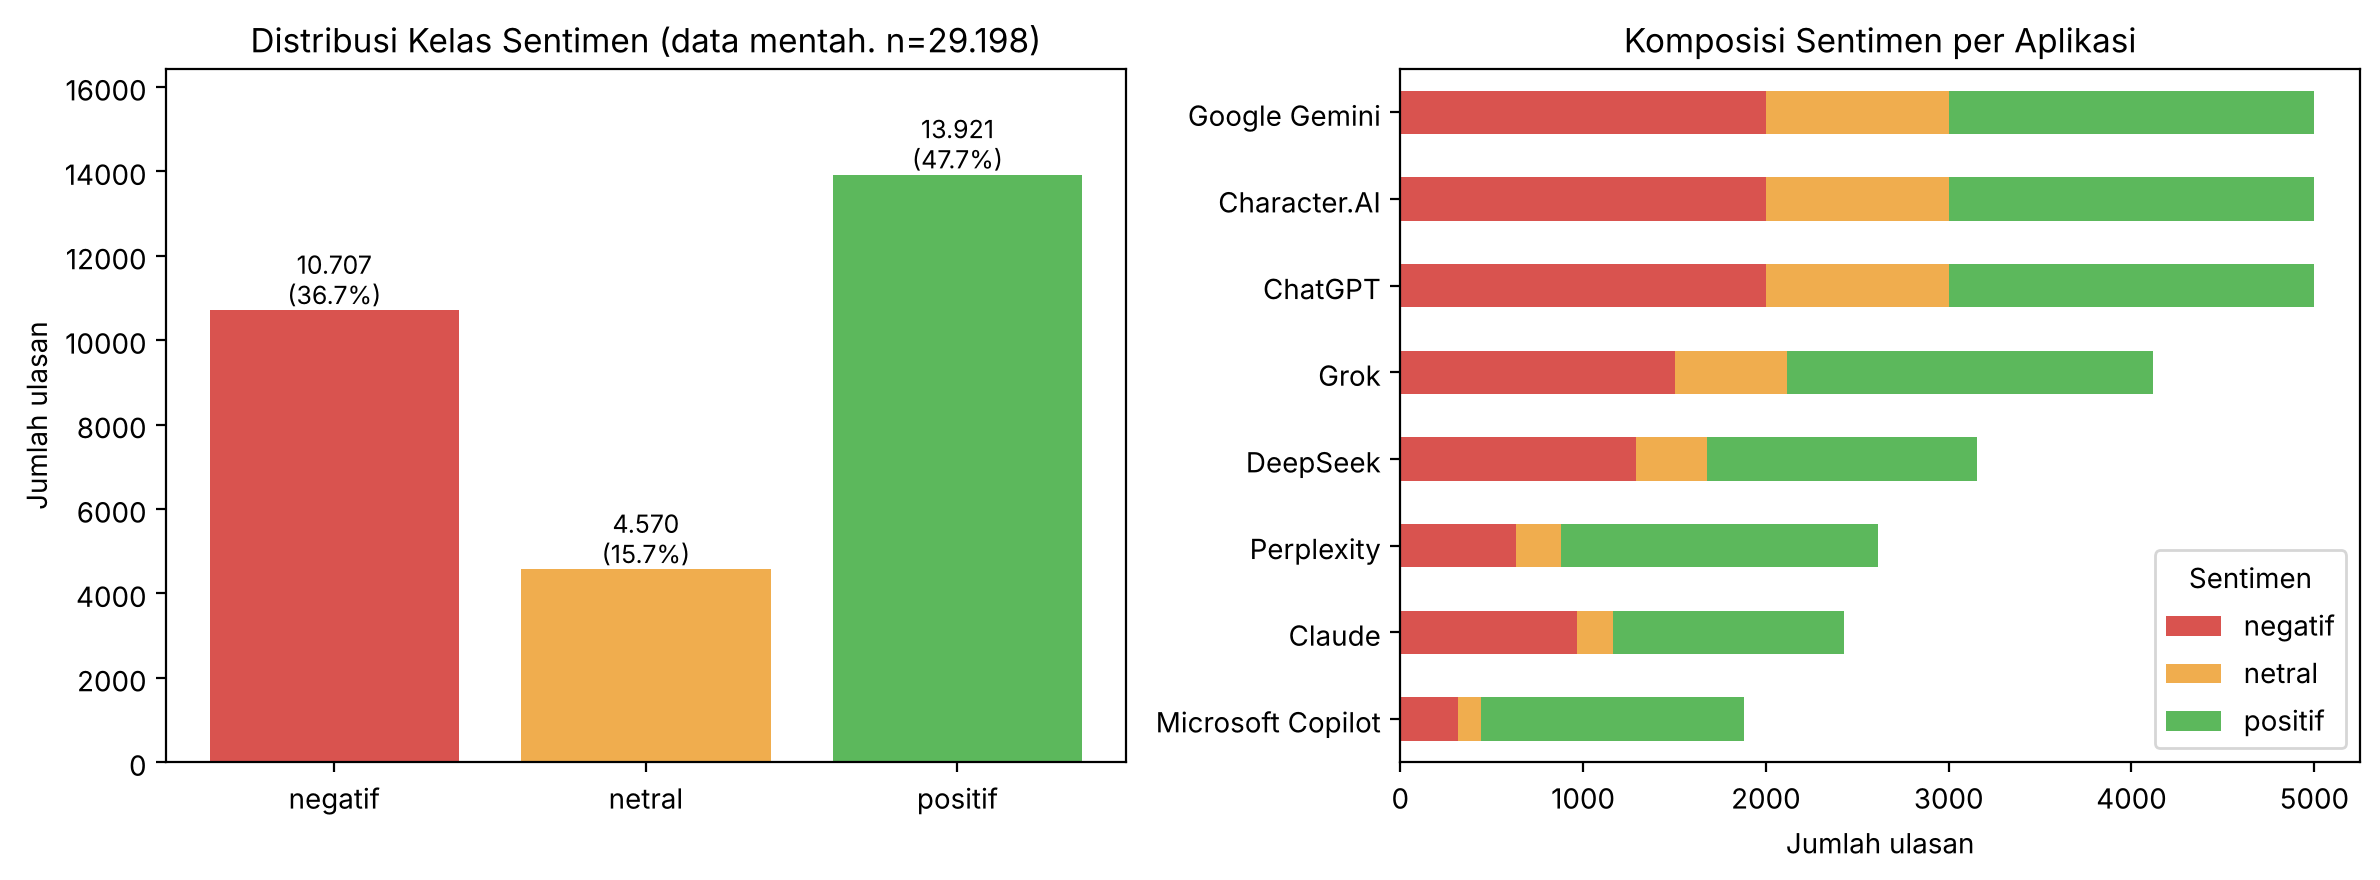

In [10]:
ct = pd.crosstab(df.appName, df.sentiment)[ORDER]
ct = ct.loc[ct.sum(1).sort_values().index]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
v = df.sentiment.value_counts()[ORDER]
bars = ax[0].bar(ORDER, v.values, color=[COL[o] for o in ORDER])
for r, x in zip(bars, v.values):
    ax[0].text(r.get_x()+r.get_width()/2, x+150, f'{x:,}\n({x/len(df)*100:.1f}%)'.replace(',', '.'), ha='center', fontsize=9)
ax[0].set_title(f'Distribusi Kelas Sentimen (data mentah, n={len(df):,})'.replace(',', '.'))
ax[0].set_ylabel('Jumlah ulasan'); ax[0].set_ylim(0, v.max()*1.18)
ct.plot.barh(stacked=True, ax=ax[1], color=[COL[o] for o in ORDER])
ax[1].set_title('Komposisi Sentimen per Aplikasi'); ax[1].set_xlabel('Jumlah ulasan'); ax[1].set_ylabel(''); ax[1].legend(title='Sentimen')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/eda_01_distribusi_kelas.png', dpi=150); plt.show()

**Insight:** dataset tidak seimbang (positif 47,7%, negatif 36,7%, netral 15,7%) dan komposisi per aplikasi berbeda (kuota tetap pada ChatGPT, Gemini, Character.AI). Kelas netral diperkirakan paling sulit, sehingga F1 macro per kelas perlu dipantau.

### Visualisasi 2 — Panjang ulasan menurut sentimen

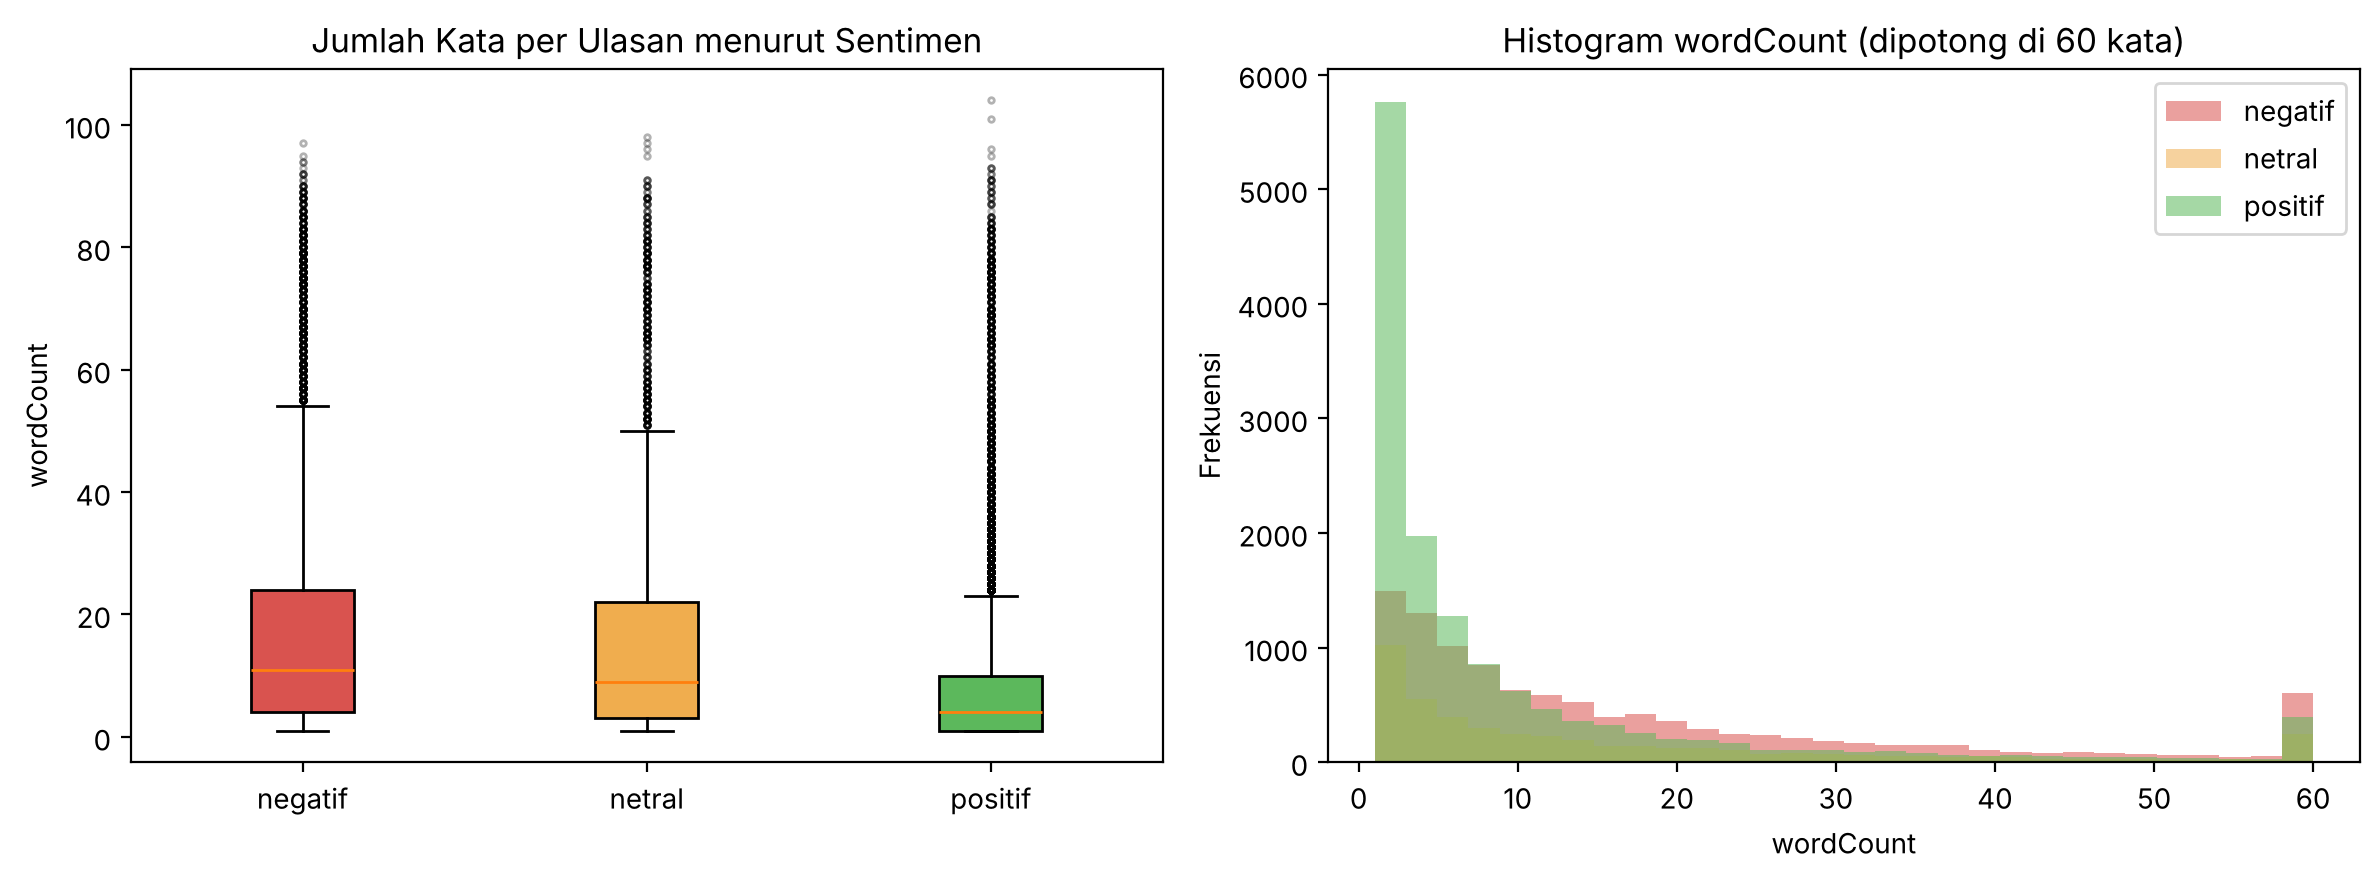

           median_kata  rata2_karakter
sentiment                             
negatif           11.0           107.6
netral             9.0            97.7
positif            4.0            59.4


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
data = [df[df.sentiment == o].wordCount for o in ORDER]
bp = ax[0].boxplot(data, tick_labels=ORDER, patch_artist=True, flierprops=dict(markersize=2, alpha=.3))
for p, o in zip(bp['boxes'], ORDER): p.set_facecolor(COL[o])
ax[0].set_title('Jumlah Kata per Ulasan menurut Sentimen'); ax[0].set_ylabel('wordCount')
for o in ORDER:
    ax[1].hist(df[df.sentiment == o].wordCount.clip(upper=60), bins=30, alpha=.55, label=o, color=COL[o])
ax[1].set_title('Histogram wordCount (dipotong di 60 kata)'); ax[1].set_xlabel('wordCount'); ax[1].set_ylabel('Frekuensi'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/eda_02_panjang_teks.png', dpi=150); plt.show()
print(df.groupby('sentiment').agg(median_kata=('wordCount', 'median'), rata2_karakter=('contentLength', 'mean')).round(1))

**Insight:** ulasan negatif dan netral jauh lebih panjang daripada positif (pengguna puas menulis singkat, yang kecewa menjelaskan masalahnya). Panjang teks informatif (dasar fitur `contentLength`) dan distribusinya miring ke kanan, sehingga panjang sekuens Bi-LSTM perlu dibatasi.

### Visualisasi 3 — Kata teratas (frekuensi) vs kata khas per kelas (log-odds)

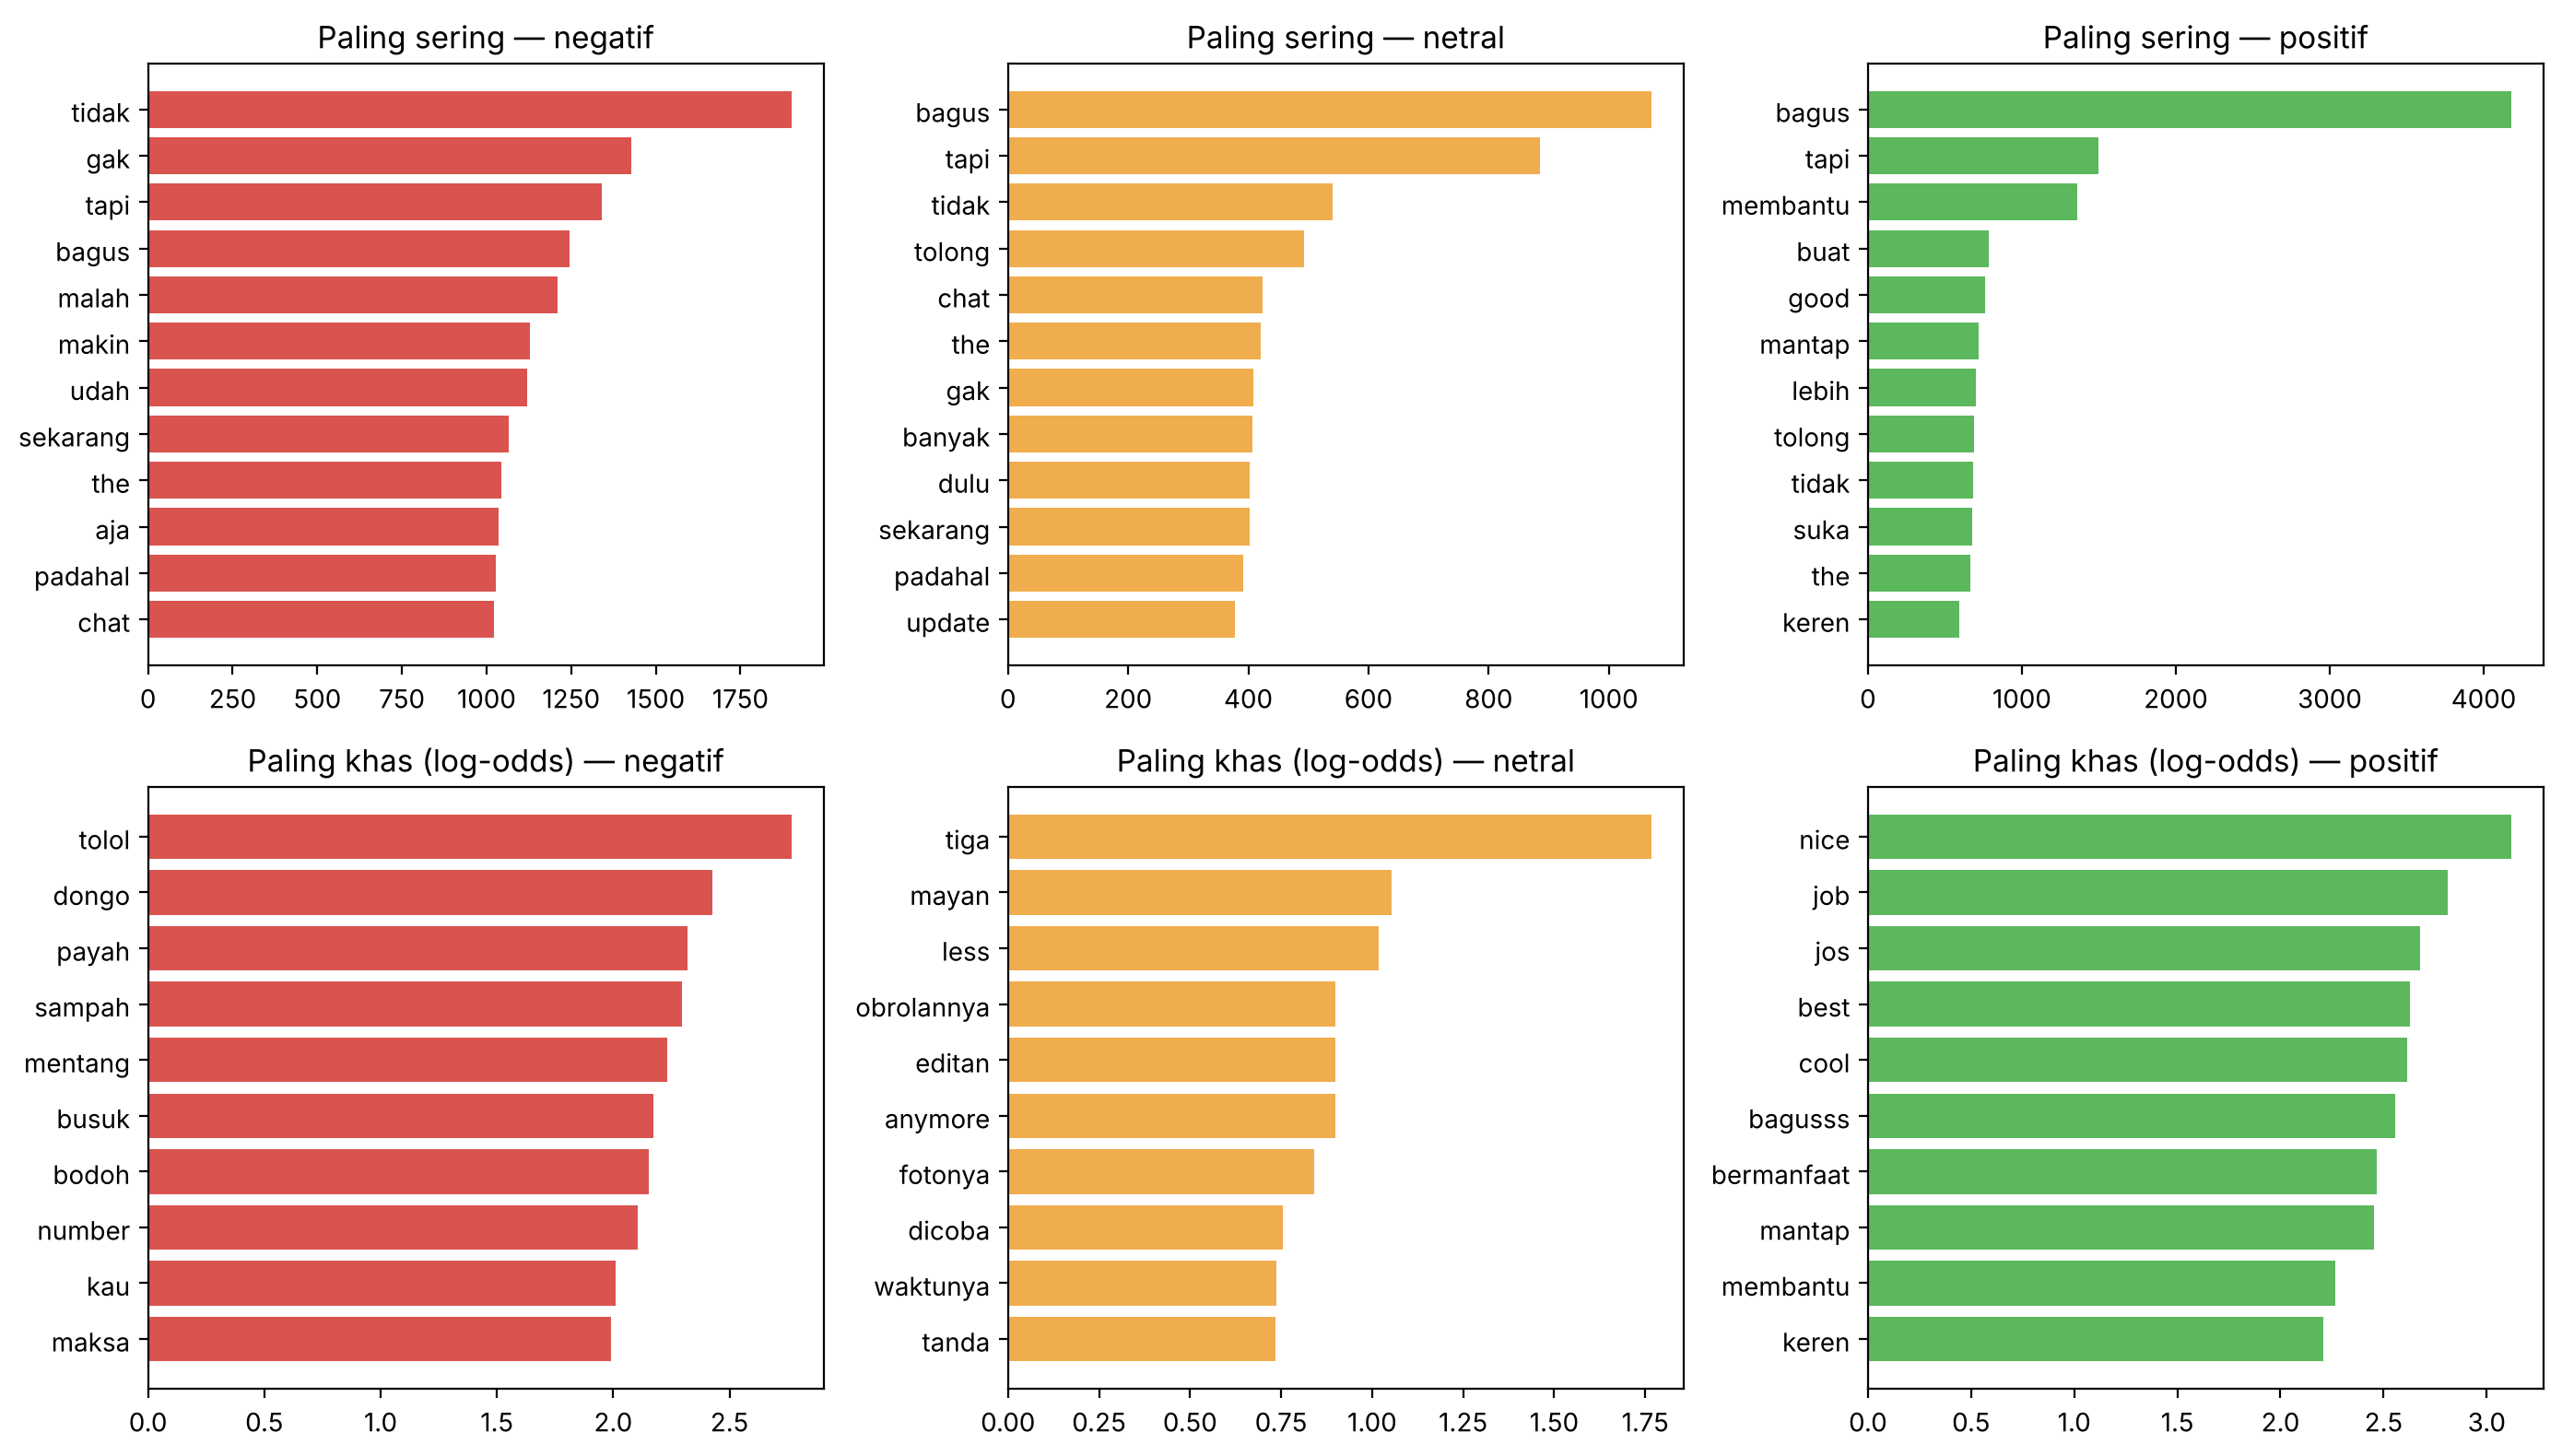

negatif | paling khas: ['tolol', 'dongo', 'payah', 'sampah', 'mentang', 'busuk', 'bodoh', 'number', 'kau', 'maksa']
netral | paling khas: ['tiga', 'mayan', 'less', 'obrolannya', 'editan', 'anymore', 'fotonya', 'dicoba', 'waktunya', 'tanda']
positif | paling khas: ['nice', 'job', 'jos', 'best', 'cool', 'bagusss', 'bermanfaat', 'mantap', 'membantu', 'keren']


In [12]:
STOP = set('yang dan di ke dari untuk dengan ini itu saya aku nya pada juga saja ada atau karena kalau jadi lagi sudah sangat banget bisa dalam sama aplikasi ai'.split())
def tokens(s):
    return [w for w in re.findall(r'[a-z]+', s.lower()) if len(w) > 2]

cnt = {o: Counter(w for s in df[df.sentiment == o].content for w in tokens(s)) for o in ORDER}

# (a) frekuensi mentah (tanpa stopword umum)
top_freq = {o: [(w, n) for w, n in cnt[o].most_common(40) if w not in STOP][:12] for o in ORDER}

# (b) log-odds: kata yang LEBIH KHAS untuk satu kelas dibanding dua kelas lain (smoothing +1, min. 30 kemunculan)
def distinctive(o, k=10, min_count=30, alpha=1.0):
    rest = Counter()
    for x in ORDER:
        if x != o: rest.update(cnt[x])
    n_o, n_r = sum(cnt[o].values()), sum(rest.values()); V = len(set(cnt[o]) | set(rest))
    sc = {w: np.log((cnt[o][w]+alpha)/(n_o+alpha*V)) - np.log((rest[w]+alpha)/(n_r+alpha*V))
          for w in set(cnt[o]) | set(rest) if cnt[o][w]+rest[w] >= min_count}
    return sorted(sc.items(), key=lambda x: -x[1])[:k][::-1]
top_dist = {o: distinctive(o) for o in ORDER}

fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for j, o in enumerate(ORDER):
    t = top_freq[o][::-1]
    ax[0, j].barh([w for w, _ in t], [n for _, n in t], color=COL[o]); ax[0, j].set_title(f'Paling sering — {o}')
    t = top_dist[o]
    ax[1, j].barh([w for w, _ in t], [s for _, s in t], color=COL[o]); ax[1, j].set_title(f'Paling khas (log-odds) — {o}')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/eda_03_kata_teratas.png', dpi=150); plt.show()
for o in ORDER: print(o, '| paling khas:', [w for w, _ in top_dist[o][::-1]])

**Insight:** baris atas (frekuensi mentah) memperlihatkan kata umum seperti "tidak" dan "tapi" muncul di ketiga kelas, sehingga kata itu sendiri tidak membedakan kelas; maknanya bergantung pada kombinasi kata (mis. "tidak bagus"), itulah alasan stopword negasi dipertahankan dan bigram/Bi-LSTM dipakai. Baris bawah (log-odds) menunjukkan kata yang benar-benar khas per kelas.